# Multivalent interface Tm — model re-fit on the droop-corrected melting temperatures

Self-contained. Reproduces today's analysis end-to-end:
1. loads the **droop-corrected, reliability-ruled Tm** (`Filtered_DF_Tm.csv`, per-construct median),
2. loads the real sequences from **`DNA Sequences.xlsx`** (22-helix layout; verified to match the old `nt5/7/9.csv`),
3. builds each interface's 22-position label by **doubling each code character** (`X`→`5`), with per-slot SantaLucia ΔH/ΔS,
4. fits the phenomenological model **and a panel of physically-motivated variants** (whole-data + 10-fold CV),
5. identifies the **best model** (N-scaled ΔS_Bond) and reports whole-data parameters ± jackknife SE,
6. tests an explicit **rotational-entropy** term,
7. generates the **theory curves** (ΔH, ΔS, bound fraction vs number of bonds and vs spacing — paper Fig 4c–f).

**Core model**
$$T_m=\frac{\sum_k g_k\,\Delta H_{NN,k}}{\sum_k g_k\,\Delta S_{NN,k}+N\,\Delta S_{Bond}+\Delta S_0+R\ln(C_T/2)}-273.15,\qquad g_k=e^{-\bar d_k/\lambda}$$

`9` is removed; `B` kept; `6` dropped (no 6nt sheet in the Excel).

In [3]:
import numpy as np, pandas as pd, os, warnings
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.stats import spearmanr
from sklearn.model_selection import KFold
warnings.filterwarnings("ignore")

# ---- physical constants ----
R_CAL=1.98720425864          # cal/mol/K
C_TILE=4.5e-9                # M  total tile concentration
EDGE=60.0                    # nm interface edge length
NSLOT=22                     # doubled label positions
SITE_NM=4                  # nm per binding site
RLN=R_CAL*np.log(C_TILE/2.0)

# ---- SantaLucia 2004 nearest-neighbor thermo (1 M NaCl) ----
NN_dH={'AA':-7.6,'AT':-7.2,'AC':-8.4,'AG':-7.8,'TA':-7.2,'TT':-7.6,'TC':-8.2,'TG':-8.5,'CA':-8.5,'CT':-7.8,'CC':-8.0,'CG':-10.6,'GA':-8.2,'GT':-8.4,'GC':-9.8,'GG':-8.0}
NN_dS={'AA':-22.2,'AT':-20.4,'AC':-22.4,'AG':-21.0,'TA':-21.3,'TT':-22.2,'TC':-22.2,'TG':-22.7,'CA':-22.7,'CT':-21.0,'CC':-19.9,'CG':-27.2,'GA':-22.2,'GT':-22.4,'GC':-24.4,'GG':-19.9}
dH_iGC,dH_iAT=0.1,2.3; dS_iGC,dS_iAT=-2.8,4.1
def duplex_thermo(seq):
    seq=str(seq).upper()
    dH=sum(NN_dH[seq[i:i+2]] for i in range(len(seq)-1)); dS=sum(NN_dS[seq[i:i+2]] for i in range(len(seq)-1))
    for e in (seq[0],seq[-1]):
        if e in 'GC': dH+=dH_iGC; dS+=dS_iGC
        else: dH+=dH_iAT; dS+=dS_iAT
    return dH,dS

In [4]:
# ---- sequences from the Excel (Tile 1 per helix, 22 helices per type) ----
xl=pd.ExcelFile('DNA Sequences.xlsx')
def _hdr(raw):
    for r in range(len(raw)):
        row=[str(x) for x in raw.iloc[r].tolist()]
        if 'Tile 1' in row: return r,{v:i for i,v in enumerate(row)}
def _parse(raw):
    hdr,cols=_hdr(raw); d={}
    for r in range(hdr+1,len(raw)):
        v=raw.iloc[r]
        try: h=int(float(v[cols['#']]))
        except: continue
        t=str(v[cols['Tile 1']]).strip().upper()
        if t and t!='NAN': d[h]=t
    return d
def parse(sh): return _parse(pd.read_excel(xl,sheet_name=sh,header=None))
SEQ={'5':parse('5nt'),'7':parse('7nt'),'9':parse('9nt'),'A':parse('A'),'B':parse('B')}
# real 6nt bonds, supplied as a separate CSV (same layout as the Excel sheets)
SEQ['6']=_parse(pd.read_csv('DNA Sequences - 6nt bonds.csv',header=None))
TH={t:{h:duplex_thermo(s) for h,s in d.items()} for t,d in SEQ.items()}
# verify the Excel odd helices match the previous on-disk nt*.csv
for typ,f in [('5','nt5.csv'),('7','nt7.csv'),('9','nt9.csv')]:
    dd=pd.read_csv(f); dd['Helix']=dd['Helix'].ffill(); disk=dd.groupby('Helix')['Sequence'].first().to_dict()
    mism=sum(SEQ[typ].get(2*k-1,'')!=str(disk.get(float(k),'')).strip().upper() for k in range(1,12))
    print(f"verify {typ}: Excel odd-helices vs nt{typ}.csv -> {'MATCH' if mism==0 else str(mism)+' mismatch'}")
# verify the 6nt bonds are reverse complements (Tile 1 vs Tile 2)
raw6=pd.read_csv('DNA Sequences - 6nt bonds.csv',header=None); h6,c6=_hdr(raw6)
comp={'A':'T','T':'A','G':'C','C':'G'}; rc=lambda s:''.join(comp[x] for x in reversed(s))
nok=ntot=0
for r in range(h6+1,len(raw6)):
    v=raw6.iloc[r]; t1=str(v[c6['Tile 1']]).strip().upper(); t2=str(v[c6['Tile 2']]).strip().upper()
    if t1 in ('','NAN'): continue
    ntot+=1; nok+=int(rc(t1)==t2)
print(f"6nt bonds: {nok}/{ntot} Tile1/Tile2 pairs are reverse complements")

verify 5: Excel odd-helices vs nt5.csv -> MATCH
verify 7: Excel odd-helices vs nt7.csv -> MATCH
verify 9: Excel odd-helices vs nt9.csv -> MATCH
6nt bonds: 22/22 Tile1/Tile2 pairs are reverse complements


In [ ]:
# --- self-contained output routing: bare outputs -> Figure4_PhenomenologicalModel/ ; never crash ---
import os as _os, pandas as _pd, matplotlib.figure as _mfig
_FIG4="Figure4_PhenomenologicalModel"
_os.makedirs(_FIG4+"/Phenomenological_Model", exist_ok=True)
def _route(p):
    p=str(p)
    if "/" not in p: p=_os.path.join(_FIG4,p)
    d=_os.path.dirname(p)
    if d: _os.makedirs(d, exist_ok=True)
    return p
_otc=_pd.DataFrame.to_csv
def _tc(self, path_or_buf=None, *a, **k):
    if isinstance(path_or_buf,str): path_or_buf=_route(path_or_buf)
    return _otc(self, path_or_buf, *a, **k)
_pd.DataFrame.to_csv=_tc
_osf=_mfig.Figure.savefig
def _sf(self, fname, *a, **k):
    if isinstance(fname,str): fname=_route(fname)
    return _osf(self, fname, *a, **k)
_mfig.Figure.savefig=_sf

In [5]:
# ---- new Tm per construct + per-bond (doubled) thermo ----
tm=pd.read_csv('Filtered_DF_Tm.csv'); tm['code']=tm['Samples'].astype(str).str.partition('.')[0]
agg=tm.groupby('code').agg(Tm_C=('Tm','median'),Tm_SE=('Tm_SE','median'),conf=('plateau_confident','first')).reset_index()
n6=agg['code'].str.contains('6').sum()
agg=agg[~agg['code'].str.contains('9')].reset_index(drop=True)   # keep 6 (real 6nt bonds now available)
def bonds(code):
    labs=[]
    for ch in code: c='5' if ch=='X' else ch; labs+=[c,c]        # double each char, X->5
    z=(np.arange(len(labs))+0.5)/len(labs)*EDGE; out=[]
    for s,lab in enumerate(labs):
        if lab=='0': continue
        th=TH.get(lab,{}).get(s+1)                               # slot s -> Excel helix s+1
        if th is None: return None
        out.append((z[s],th[0],th[1], 0 if lab in set('7AB') else 1))  # flag: 1=short(5/6nt)
    return out
agg['B']=agg['code'].apply(bonds)
agg=agg[agg['B'].notna() & agg['B'].apply(lambda b:len(b)>0)].reset_index(drop=True)
Bl=list(agg['B']); Y=agg['Tm_C'].values.astype(float); SE=agg['Tm_SE'].values.astype(float); CONF=(agg['conf']=='high').values
n=len(Bl)
print(f"removed 9; now INCLUDED {n6} constructs with '6' ; kept 5/6/X/7/A/B")
print(f"constructs fit: {n}  ({CONF.sum()} high-confidence)")

removed 9; now INCLUDED 5 constructs with '6' ; kept 5/6/X/7/A/B
constructs fit: 235  (208 high-confidence)


## Models: the base formula and physically-motivated variants

Each fit on the whole dataset and scored by 10-fold cross-validation (the honest generalization metric).

In [6]:
def gk(b,lam,mode='mean'):
    z=np.array([x[0] for x in b])
    if len(z)==1: return np.array([1.0])
    if mode=='mean': d=np.array([np.mean(np.abs(np.delete(z,i)-z[i])) for i in range(len(z))])
    else:            d=np.array([np.min(np.abs(np.delete(z,i)-z[i])) for i in range(len(z))])
    return np.exp(-d/lam)
def predict(b,p,variant):
    if variant in ('mean','nn'):
        lam,dSb,base=p; g=gk(b,lam,variant)
        dH=sum(gi*x[1] for gi,x in zip(g,b)); dS=sum(gi*(x[2]+dSb) for gi,x in zip(g,b))
        return (dH*1000)/(dS+base+RLN)-273.15
    if variant=='hOnly':
        lam,dSb,base=p; g=gk(b,lam)
        dH=sum(gi*x[1] for gi,x in zip(g,b)); dS=sum(x[2] for x in b)+len(b)*dSb
        return (dH*1000)/(dS+base+RLN)-273.15
    if variant=='Nscale':          # BEST: g-weighted ΔH/ΔS_NN but N-scaled ΔS_Bond
        lam,dSb,base=p; g=gk(b,lam)
        dH=sum(gi*x[1] for gi,x in zip(g,b)); dS=sum(gi*x[2] for gi,x in zip(g,b))+len(b)*dSb
        return (dH*1000)/(dS+base+RLN)-273.15
    if variant=='pertype':
        lam,dSb_s,dSb_l,base=p; g=gk(b,lam)
        dH=sum(gi*x[1] for gi,x in zip(g,b)); dS=sum(gi*(x[2]+(dSb_s if x[3] else dSb_l)) for gi,x in zip(g,b))
        return (dH*1000)/(dS+base+RLN)-273.15
    if variant=='splitlam':
        lamH,lamS,dSb,base=p; gH=gk(b,lamH); gS=gk(b,lamS)
        dH=sum(gi*x[1] for gi,x in zip(gH,b)); dS=sum(gi*(x[2]+dSb) for gi,x in zip(gS,b))
        return (dH*1000)/(dS+base+RLN)-273.15
P0={'mean':[120,-8,5],'nn':[120,-8,5],'hOnly':[120,-8,5],'Nscale':[120,-8,5],'pertype':[120,-8,-8,5],'splitlam':[120,120,-8,5]}
LB={k:([1,-60,-200] if len(v)==3 else [1,-60,-60,-200] if k=='pertype' else [1,1,-60,-200]) for k,v in P0.items()}
UB={k:([1000,5,400] if len(v)==3 else [1000,5,5,400] if k=='pertype' else [1000,1000,5,400]) for k,v in P0.items()}
def fit(variant,idx=None,w=None):
    I=range(n) if idx is None else idx
    def resid(p):
        r=[predict(Bl[i],p,variant)-Y[i] for i in I]
        return [ri*np.sqrt(w[i]) for ri,i in zip(r,I)] if w is not None else r
    return least_squares(resid,P0[variant],bounds=(LB[variant],UB[variant])).x
def metrics(variant,p,idx=None):
    I=list(range(n)) if idx is None else list(idx); pred=np.array([predict(Bl[i],p,variant) for i in I]); y=Y[I]; e=pred-y
    return np.sqrt(np.mean(e**2)),1-np.sum(e**2)/np.sum((y-y.mean())**2),spearmanr(y,pred).correlation
def cv(variant,w=None,subset=None):
    I=np.arange(n) if subset is None else np.where(subset)[0]
    oof=np.full(len(I),np.nan)
    for tr,te in KFold(10,shuffle=True,random_state=0).split(I):
        p=fit(variant,idx=I[tr],w=w)
        for j in te: oof[j]=predict(Bl[I[j]],p,variant)
    y=Y[I]; e=oof-y
    return np.sqrt(np.mean(e**2)),spearmanr(y,oof).correlation

In [7]:
rows=[]
specs=[('mean','mean-dist g (base)'),('Nscale','N-scaled dS_Bond'),('hOnly','g on dH only'),
       ('splitlam','split lamH/lamS'),('pertype','per-type dS_Bond'),('nn','nearest-nbr g')]
for v,lab in specs:
    p=fit(v); fr=metrics(v,p); cr=cv(v)
    rows.append([lab,round(fr[0],3),round(fr[1],3),round(fr[2],3),round(cr[0],3),round(cr[1],3),str(np.round(p,2))])
# SE-weighted + high-confidence subset of the base model
w=1.0/np.clip(SE,0.1,None)**2
p=fit('mean',w=w); fr=metrics('mean',p); cr=cv('mean',w=w)
rows.append(['mean + SE-weighted',round(fr[0],3),round(fr[1],3),round(fr[2],3),round(cr[0],3),round(cr[1],3),str(np.round(p,2))])
p=fit('mean',idx=np.where(CONF)[0]); fr=metrics('mean',p,idx=np.where(CONF)[0]); cr=cv('mean',subset=CONF)
rows.append([f'mean high-conf (n={CONF.sum()})',round(fr[0],3),round(fr[1],3),round(fr[2],3),round(cr[0],3),round(cr[1],3),str(np.round(p,2))])
comp=pd.DataFrame(rows,columns=['model','fitRMS','fitR2','fitrho','cvRMS','cvrho','params'])
comp.to_csv('model_comparison_newTm.csv',index=False)
print(comp.to_string(index=False))

                 model  fitRMS  fitR2  fitrho  cvRMS  cvrho                        params
    mean-dist g (base)   2.044  0.793   0.879  2.084  0.876        [ 53.15 -10.07  16.05]
      N-scaled dS_Bond   1.954  0.811   0.887  1.984  0.884        [139.82  -8.13   5.24]
          g on dH only   2.035  0.795   0.887  2.052  0.886     [1000.     -7.27    4.23]
       split lamH/lamS   1.989  0.804   0.882  2.044  0.878 [484.01 754.06  -8.1    5.52]
      per-type dS_Bond   2.004  0.801   0.877  2.044  0.873     [57.54 -9.94 -9.19 11.82]
         nearest-nbr g   2.546  0.679   0.752  2.561  0.748     [1000.    -10.6     5.93]
    mean + SE-weighted   2.070  0.788   0.882  2.090  0.881        [ 43.98 -10.31  19.75]
mean high-conf (n=208)   2.035  0.767   0.865  2.071  0.859           [57.72 -9.95 14.19]


## Best model: N-scaled ΔS_Bond — whole-dataset parameters ± jackknife SE

In [8]:
p=fit('Nscale'); rms,r2,rho=metrics('Nscale',p)
# jackknife (leave-one-out) SE
J=np.array([fit('Nscale',idx=[k for k in range(n) if k!=i]) for i in range(n)])
se=np.sqrt((n-1)/n*np.sum((J-J.mean(0))**2,0))
print("BEST MODEL (N-scaled dS_Bond), fit on ENTIRE dataset (n=%d):"%n)
print(f"  lambda   = {p[0]:7.2f} +/- {se[0]:.2f} nm")
print(f"  dS_Bond  = {p[1]:+7.3f} +/- {se[1]:.3f} cal/mol/K")
print(f"  dS_0     = {p[2]:+7.3f} +/- {se[2]:.3f} cal/mol/K")
print(f"  whole-data: RMS={rms:.3f} C   R2={r2:.3f}   rho={rho:.3f}")
BEST=dict(lam=p[0],dSb=p[1],base=p[2])
agg['Tm_pred']= [predict(b,p,'Nscale') for b in Bl]
agg[['code','Tm_C','Tm_pred']].to_csv('interfaces_newTm_bestmodel.csv',index=False)
print("saved interfaces_newTm_bestmodel.csv")

BEST MODEL (N-scaled dS_Bond), fit on ENTIRE dataset (n=235):
  lambda   =  139.82 +/- 12.34 nm
  dS_Bond  =  -8.131 +/- 0.192 cal/mol/K
  dS_0     =  +5.237 +/- 1.472 cal/mol/K
  whole-data: RMS=1.954 C   R2=0.811   rho=0.887
saved interfaces_newTm_bestmodel.csv


In [ ]:
# ===== SI Table S1: parameter uncertainty for the best (N-scaled) phenomenological model =====
# Jackknife (leave-one-construct-out) standard errors + bootstrap (resample constructs with
# replacement) 95% confidence intervals for the three fitted parameters: lambda, dS_Bond, dS_0.
import os
PNAMES=["lambda_nm","dS_Bond_cal_mol_K","dS_0_cal_mol_K"]
# jackknife SE (se) and point estimate (p) are from the cell above
rng=np.random.default_rng(0)
B=1000
boot=np.empty((B,len(p)))
for bi in range(B):
    boot[bi]=fit('Nscale', idx=rng.integers(0,n,n))
boot_se=boot.std(0,ddof=1); boot_mean=boot.mean(0)
ci_lo=np.percentile(boot,2.5,axis=0); ci_hi=np.percentile(boot,97.5,axis=0)
ciTab=pd.DataFrame({"parameter":PNAMES,"point_estimate":p,
                    "jackknife_SE":se,"bootstrap_SE":boot_se,"bootstrap_mean":boot_mean,
                    "boot_CI95_low":ci_lo,"boot_CI95_high":ci_hi,
                    "n_constructs":n,"n_bootstrap":B}).round(4)
for _d in ("Supplementary/TableS1_Model_Comparison_All",
           "Figure4_PhenomenologicalModel/Phenomenological_Model"):
    os.makedirs(_d,exist_ok=True)
    ciTab.to_csv(_d+"/phenomenological_parameter_CIs.csv",index=False)
print("saved phenomenological_parameter_CIs.csv (jackknife SE + bootstrap 95% CI) for SI Table S1")
print(ciTab.to_string(index=False))

## Does an explicit rotational-entropy penalty help?

Add $-k_{rot}R\ln(1+I)$ to the denominator, $I=\sum_k(z_k-\bar z)^2$ (moment of inertia of bond positions).

In [9]:
def inertia(b):
    z=np.array([x[0] for x in b]); return np.sum((z-z.mean())**2)
def predict_rot(b,p):
    lam,dSb,base,krot=p; g=gk(b,lam)
    dH=sum(gi*x[1] for gi,x in zip(g,b)); dS=sum(gi*x[2] for gi,x in zip(g,b))+len(b)*dSb
    Srot=-krot*R_CAL*np.log(1.0+inertia(b))
    return (dH*1000)/(dS+base+RLN+Srot)-273.15
def fit_rot(idx=None):
    I=range(n) if idx is None else idx
    return least_squares(lambda q:[predict_rot(Bl[i],q)-Y[i] for i in I],[120,-8,5,0.1],bounds=([1,-60,-200,-5],[1000,5,400,20])).x
pr=fit_rot(); predr=np.array([predict_rot(b,pr) for b in Bl]); e=predr-Y
rms_r=np.sqrt(np.mean(e**2)); r2_r=1-np.sum(e**2)/np.sum((Y-Y.mean())**2)
oof=np.full(n,np.nan)
for tr,te in KFold(10,shuffle=True,random_state=0).split(np.arange(n)):
    q=fit_rot(idx=tr)
    for j in te: oof[j]=predict_rot(Bl[j],q)
cv_r=np.sqrt(np.mean((oof-Y)**2))
Jr=np.array([fit_rot(idx=[k for k in range(n) if k!=i]) for i in range(n)]); se_kr=np.sqrt((n-1)/n*np.sum((Jr-Jr.mean(0))**2,0))[3]
print("N-scaled + rotational term:  fitRMS=%.3f R2=%.3f  cvRMS=%.3f  k_rot=%.3f +/- %.3f"%(rms_r,r2_r,cv_r,pr[3],se_kr))
print("-> k_rot consistent with 0 and no CV gain: the rotational penalty is degenerate with lambda/dS_0 in this 1D geometry.")

N-scaled + rotational term:  fitRMS=1.947 R2=0.813  cvRMS=2.001  k_rot=-0.861 +/- 0.994
-> k_rot consistent with 0 and no CV gain: the rotational penalty is degenerate with lambda/dS_0 in this 1D geometry.


## Theory curves from the best model (paper Fig 4c–f)

Representative 7nt bonds; $\theta$ at a 40 °C reference.

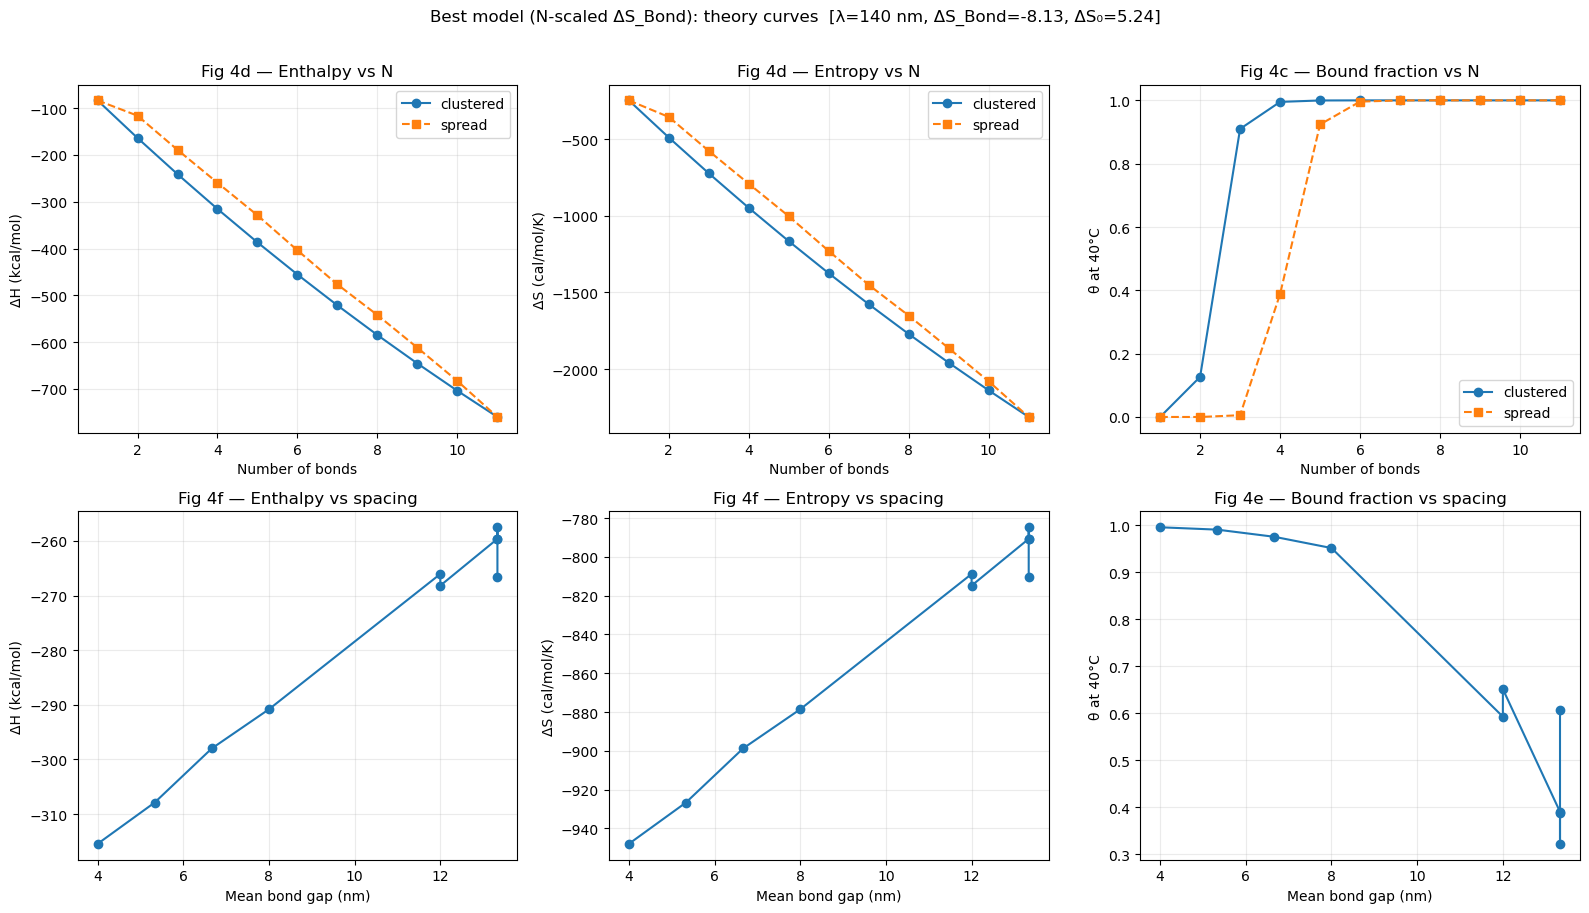

saved theory_vs_Nbonds.csv, theory_vs_spacing.csv, theory_fig4_cdef.svg


In [10]:
DH7=np.mean([v[0] for v in TH['7'].values()]); DS7=np.mean([v[1] for v in TH['7'].values()])
def zslots(cp):
    sl=[]; [sl.extend([2*i,2*i+1]) for i in cp]; return np.array([(s+0.5)/NSLOT*EDGE for s in sl])
def thermo7(cp):
    z=zslots(cp); Ns=len(z)
    g=np.array([1.0]) if Ns==1 else np.exp(-np.array([np.mean(np.abs(np.delete(z,i)-z[i])) for i in range(Ns)])/BEST['lam'])
    dH=np.sum(g*DH7); dS=np.sum(g*DS7)+Ns*BEST['dSb']+BEST['base']
    Tm=dH*1000/(dS+RLN)-273.15; return dH,dS,Tm
def theta(T_C,dH,dS):
    T=T_C+273.15; u=np.exp(-(dH*1000-T*dS)/(R_CAL*T))*C_TILE
    disc=np.maximum((2*u+1)**2-4*u*u,0); return float(np.clip(((2*u+1)-np.sqrt(disc))/(2*u),0,1))
Tref=40.0
# vs number of bonds (clustered & spread)
rN=[]
for N in range(1,12):
    for arr,lab in [(list(range(N)),'clustered'),(sorted(set(round(k*10/max(N-1,1)) for k in range(N))),'spread')]:
        dH,dS,Tm=thermo7(arr); rN.append(dict(N=N,arrangement=lab,dH_kcal=dH,dS_cal=dS,Tm_C=Tm,theta_40C=theta(Tref,dH,dS)))
dN=pd.DataFrame(rN); dN.to_csv('theory_vs_Nbonds.csv',index=False)
# vs spacing (N=4)
arrs=[[0,1,2,3],[0,1,2,4],[0,1,3,5],[0,2,4,6],[0,1,5,9],[0,3,6,9],[0,2,6,10],[0,3,7,10],[0,1,6,10],[0,3,4,10]]
rS=[{'meangap_nm':np.mean(np.diff(sorted(a)))*SITE_NM,'dH_kcal':thermo7(a)[0],'dS_cal':thermo7(a)[1],'Tm_C':thermo7(a)[2],'theta_40C':theta(Tref,*thermo7(a)[:2])} for a in arrs]
dS_=pd.DataFrame(rS).sort_values('meangap_nm'); dS_.to_csv('theory_vs_spacing.csv',index=False)

fig,ax=plt.subplots(2,3,figsize=(16,9))
for lab,mk in [('clustered','o-'),('spread','s--')]:
    d=dN[dN.arrangement==lab]
    ax[0,0].plot(d.N,d.dH_kcal,mk,label=lab); ax[0,1].plot(d.N,d.dS_cal,mk,label=lab); ax[0,2].plot(d.N,d.theta_40C,mk,label=lab)
ax[0,0].set(xlabel='Number of bonds',ylabel='ΔH (kcal/mol)',title='Fig 4d — Enthalpy vs N')
ax[0,1].set(xlabel='Number of bonds',ylabel='ΔS (cal/mol/K)',title='Fig 4d — Entropy vs N')
ax[0,2].set(xlabel='Number of bonds',ylabel='θ at 40°C',title='Fig 4c — Bound fraction vs N')
ax[1,0].plot(dS_.meangap_nm,dS_.dH_kcal,'o-'); ax[1,0].set(xlabel='Mean bond gap (nm)',ylabel='ΔH (kcal/mol)',title='Fig 4f — Enthalpy vs spacing')
ax[1,1].plot(dS_.meangap_nm,dS_.dS_cal,'o-'); ax[1,1].set(xlabel='Mean bond gap (nm)',ylabel='ΔS (cal/mol/K)',title='Fig 4f — Entropy vs spacing')
ax[1,2].plot(dS_.meangap_nm,dS_.theta_40C,'o-'); ax[1,2].set(xlabel='Mean bond gap (nm)',ylabel='θ at 40°C',title='Fig 4e — Bound fraction vs spacing')
for a in ax.ravel():
    a.grid(alpha=0.25)
    if a.get_legend_handles_labels()[0]: a.legend()
fig.suptitle('Best model (N-scaled ΔS_Bond): theory curves  [λ=%.0f nm, ΔS_Bond=%.2f, ΔS₀=%.2f]'%(BEST['lam'],BEST['dSb'],BEST['base']),y=1.01)
plt.tight_layout(); plt.savefig('theory_fig4_cdef.svg',bbox_inches='tight'); plt.show()
print('saved theory_vs_Nbonds.csv, theory_vs_spacing.csv, theory_fig4_cdef.svg')

## Explore the model: design your own interfaces

Uses the **best model (N-scaled ΔS_Bond)** and its fitted parameters `FIT` (from the best-model cell above). Specify bonds by duplex length, number, and spacing; `make_interface(...)` builds a design and each physical bond is **doubled** (two slots, matching the fit convention). Change anything and re-run.

In [11]:
import seaborn as sns
sns.set_theme(style="white", context="talk")

# best-model fitted parameters (N-scaled dS_Bond)
FIT = dict(lam=BEST['lam'], dS_int=BEST['dSb'], base=BEST['base'])
print("N-scaled best-model params in use:", {k: round(v, 3) for k, v in FIT.items()})

# representative per-length bond thermo = mean over the 22 Excel helices of that type
def _rep_thermo(L):
    t = {5: '5', 7: '7', 9: '9'}.get(int(L), '7'); v = list(TH[t].values())
    return np.mean([x[0] for x in v]), np.mean([x[1] for x in v])

def _meand(z):
    z = np.asarray(z, float)
    if len(z) <= 1: return np.zeros(len(z))
    return np.array([np.mean(np.abs(np.delete(z, i) - z[i])) for i in range(len(z))])

# n_bonds of a given duplex length, evenly spaced (or by spacing_nm).
# Each physical bond -> two doubled slots (the fit convention).
def make_interface(n_bonds, duplex_len=7, spacing_nm=None, center_nm=None, edge=EDGE):
    if center_nm is None: center_nm = edge / 2
    if spacing_nm is None:
        span = 0.8 * edge
        xs = np.linspace(center_nm - span/2, center_nm + span/2, n_bonds) if n_bonds > 1 else [center_nm]
    else:
        total = (n_bonds - 1) * spacing_nm
        xs = [center_nm - total/2 + k*spacing_nm for k in range(n_bonds)]
    dH, dS = _rep_thermo(duplex_len)
    bonds = []
    for x in xs: bonds += [(x, dH, dS), (x, dH, dS)]
    return bonds

def _g(bonds): return np.exp(-_meand([b[0] for b in bonds]) / FIT['lam'])

def predict_Tm(bonds, C=None):
    C = C_TILE if C is None else C
    g = _g(bonds); dH = sum(gi*b[1] for gi, b in zip(g, bonds)); dS = sum(gi*b[2] for gi, b in zip(g, bonds))
    dS_eff = dS + len(bonds)*FIT['dS_int'] + FIT['base'] + R_CAL*np.log(C/2.0)
    return dH*1000.0/dS_eff - 273.15

# melting curve -> (T_C, fraction bound)
def predict_Tm1(bonds, C=None):
    C = C_TILE if C is None else C
    if not bonds: return np.array([]), np.array([])
    g = _g(bonds); dH = sum(gi*b[1] for gi, b in zip(g, bonds)); dS = sum(gi*b[2] for gi, b in zip(g, bonds))
    dS_eff = dS + len(bonds)*FIT['dS_int'] + FIT['base'] + R_CAL*np.log(C/2.0)
    T_C = np.linspace(25, 55, 500); T_K = T_C + 273.15
    dG = dH*1000.0 - T_K*dS_eff; K = np.exp(-dG/(R_CAL*T_K)); return T_C, K/(1+K)

# -> (dH kcal/mol, dS_eff cal/mol/K)
def predict_Tm2(bonds, C=None):
    C = C_TILE if C is None else C
    if not bonds: return np.array([]), np.array([])
    g = _g(bonds); dH = sum(gi*b[1] for gi, b in zip(g, bonds)); dS = sum(gi*b[2] for gi, b in zip(g, bonds))
    dS_eff = dS + len(bonds)*FIT['dS_int'] + FIT['base'] + R_CAL*np.log(C/2.0)
    return dH, dS_eff

bonds = make_interface(5, duplex_len=7, spacing_nm=3)


N-scaled best-model params in use: {'lam': 139.821, 'dS_int': -8.131, 'base': 5.237}


(25.0, 55.0)

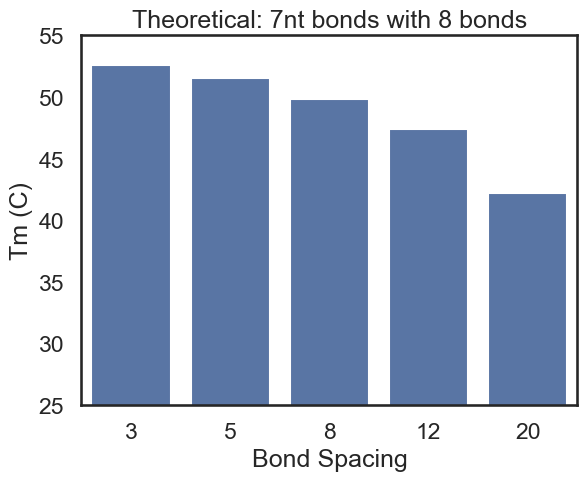

In [12]:
tm = []
for sp in [3,5,8,12,20]:
    bonds=make_interface(8, duplex_len=7, spacing_nm=sp)
    tm.append(predict_Tm(bonds))
    #print(f"    spacing {sp:2d} nm: Tm = {predict_Tm(bonds):.1f} C  "
    #f"(mean interbond dist drives colocalization)")

sns.barplot(x = [3,5,8,12,20], y = tm)
plt.ylabel('Tm (C)')
plt.title('Theoretical: 7nt bonds with 8 bonds')
plt.xlabel('Bond Spacing')
plt.ylim(25,55)

Text(0.5, 0, 'Bond Spacing')

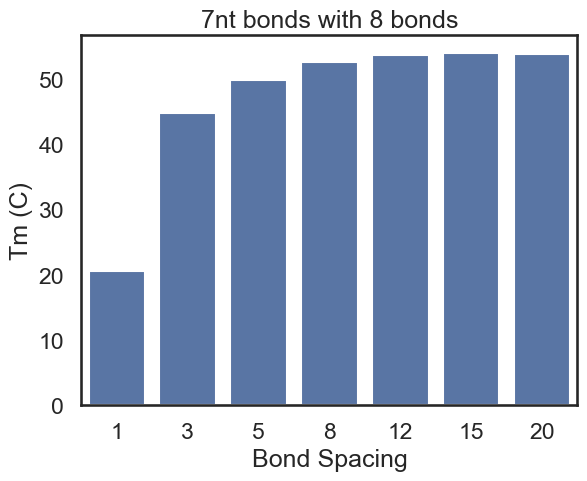

In [13]:
tm = []
for sp in [1,3,5,8,12,15,20]:
    bonds=make_interface(sp, duplex_len=7, spacing_nm=3)
    tm.append(predict_Tm(bonds))
    #print(f"    spacing {sp:2d} nm: Tm = {predict_Tm(bonds):.1f} C  "
    #f"(mean interbond dist drives colocalization)")

sns.barplot(x = [1,3,5,8,12,15,20], y = tm)
plt.ylabel('Tm (C)')
plt.title('7nt bonds with 8 bonds')
plt.xlabel('Bond Spacing')
#plt.ylim(25,55)

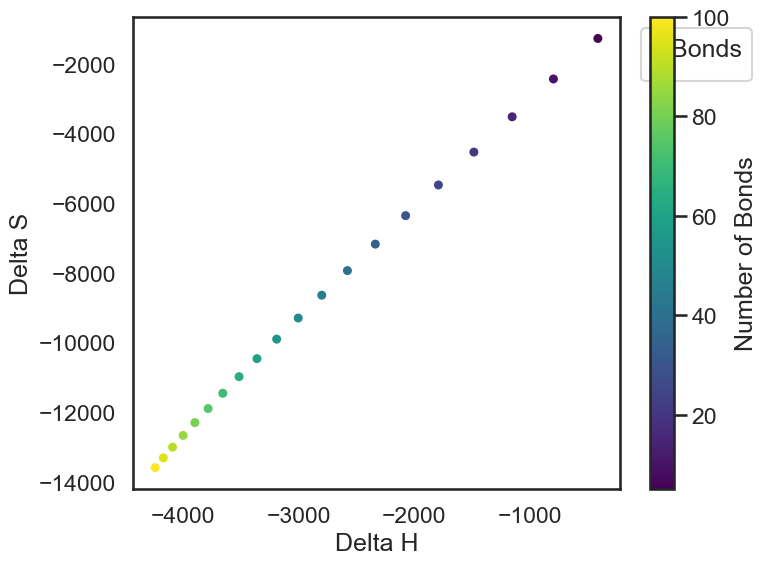

In [14]:
sps = np.linspace(5,100,20)

# perceptually uniform colormap
cmap = plt.cm.viridis
norm = plt.Normalize(min(sps), max(sps))

fig, ax = plt.subplots(figsize=(8, 6))

dh=list()
ds = list()
for sp in sps:
    bonds = make_interface(int(sp), duplex_len=7, spacing_nm=3)
    T, f = predict_Tm2(bonds)
    dh.append(T)
    ds.append(f)

sns.scatterplot(
    x=dh,
    y=ds,
    ax=ax,
    color=cmap(norm(sps)),
    linewidth=2.5,
    #label=f"{sp} bonds"
)

ax.set_xlabel("Delta H")
ax.set_ylabel("Delta S")
#ax.set_ylim(-0.05, 1.05)
ax.legend(title="# Bonds", bbox_to_anchor=(1.02, 1), loc="upper left")

# colorbar showing bond count
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Number of Bonds")

plt.tight_layout()
plt.show()

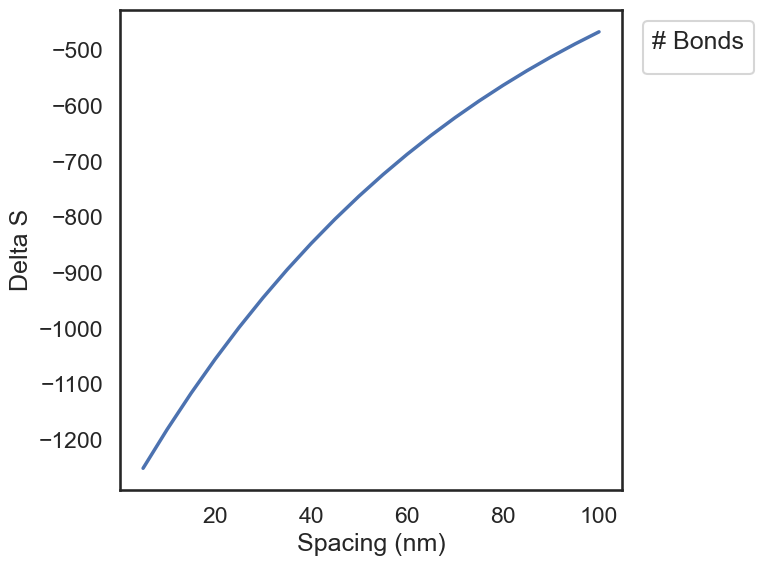

In [15]:
sps = np.linspace(5,100,20)

# perceptually uniform colormap
cmap = plt.cm.viridis
norm = plt.Normalize(min(sps), max(sps))

fig, ax = plt.subplots(figsize=(8, 6))

dh=list()
ds = list()
for sp in sps:
    bonds = make_interface(5, duplex_len=7, spacing_nm=int(sp))
    T, f = predict_Tm2(bonds)
    dh.append(T)
    ds.append(f)

sns.lineplot(
    x=sps,
    y=ds,
    ax=ax,
    #color=cmap(norm(sps)),
    linewidth=2.5,
    #label=f"{sp} bonds"
)

ax.set_xlabel("Spacing (nm)")
ax.set_ylabel("Delta S")
#ax.set_ylim(-0.05, 1.05)
ax.legend(title="# Bonds", bbox_to_anchor=(1.02, 1), loc="upper left")

# colorbar showing bond count
#sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
#sm.set_array([])
#cbar = plt.colorbar(sm, ax=ax)
#cbar.set_label("Number of Bonds")

plt.tight_layout()
plt.show()

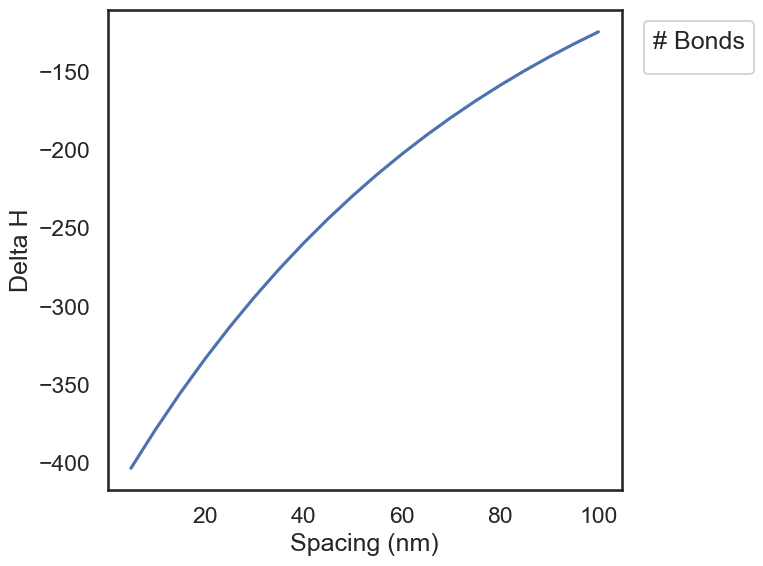

In [16]:
sps = np.linspace(5,100,20)

# perceptually uniform colormap
cmap = plt.cm.viridis
norm = plt.Normalize(min(sps), max(sps))

fig, ax = plt.subplots(figsize=(8, 6))

dh=list()
ds = list()
for sp in sps:
    bonds = make_interface(5, duplex_len=7, spacing_nm=int(sp))
    T, f = predict_Tm2(bonds)
    dh.append(T)
    ds.append(f)

sns.lineplot(
    x=sps,
    y=dh,
    ax=ax,
    #color=cmap(norm(sps)),
    #linewidth=2.5,
    #label=f"{sp} bonds"
)

ax.set_xlabel("Spacing (nm)")
ax.set_ylabel("Delta H")
#ax.set_ylim(-0.05, 1.05)
ax.legend(title="# Bonds", bbox_to_anchor=(1.02, 1), loc="upper left")

# colorbar showing bond count
#sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
#sm.set_array([])
#cbar = plt.colorbar(sm, ax=ax)
#cbar.set_label("Number of Bonds")

plt.tight_layout()
plt.show()

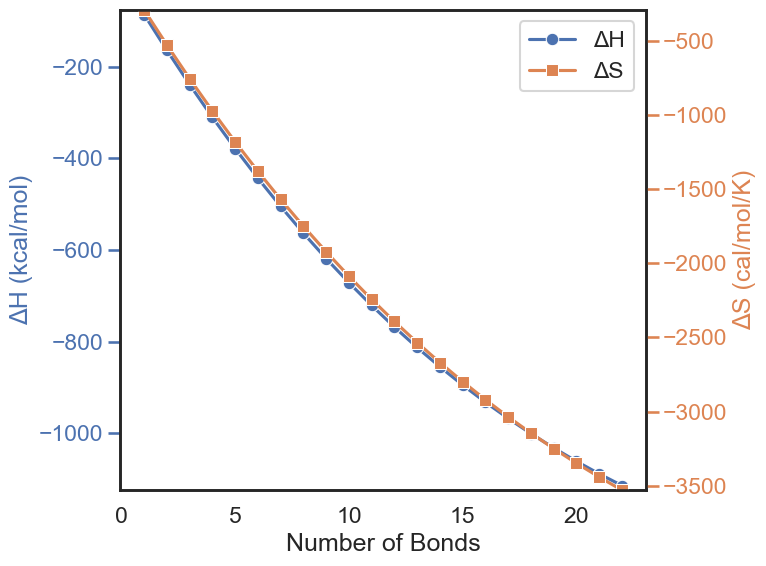

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sps = np.linspace(1, 22, 22)

dh = []
ds = []

for sp in sps:
    bonds = make_interface(int(sp), duplex_len=7, spacing_nm=10)
    H, S = predict_Tm2(bonds)
    dh.append(H)
    ds.append(S)

fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()

# ΔH on left axis
sns.lineplot(
    x=sps,
    y=dh,
    ax=ax1,
    marker="o",
    label="ΔH"
)

# ΔS on right axis
sns.lineplot(
    x=sps,
    y=ds,
    ax=ax2,
    marker="s",
    label="ΔS",
    color = 'C1'
)

ax1.set_xlabel("Number of Bonds")
ax1.set_ylabel("ΔH (kcal/mol)")
ax2.set_ylabel("ΔS (cal/mol/K)")
if ax1.get_legend() is not None:
    ax1.get_legend().remove()

if ax2.get_legend() is not None:
    ax2.get_legend().remove()
# combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="best"
)

ax1.set_ylim(min(dh) - 10, max(dh) + 10)
ax2.set_ylim(min(ds), max(ds))

ax1.set_ylabel("ΔH (kcal/mol)", color="C0")
ax2.set_ylabel("ΔS (cal/mol/K)", color="C1")
ax1.tick_params(axis="y", colors="C0")
ax2.tick_params(axis="y", colors="C1")
plt.tight_layout()
plt.show()

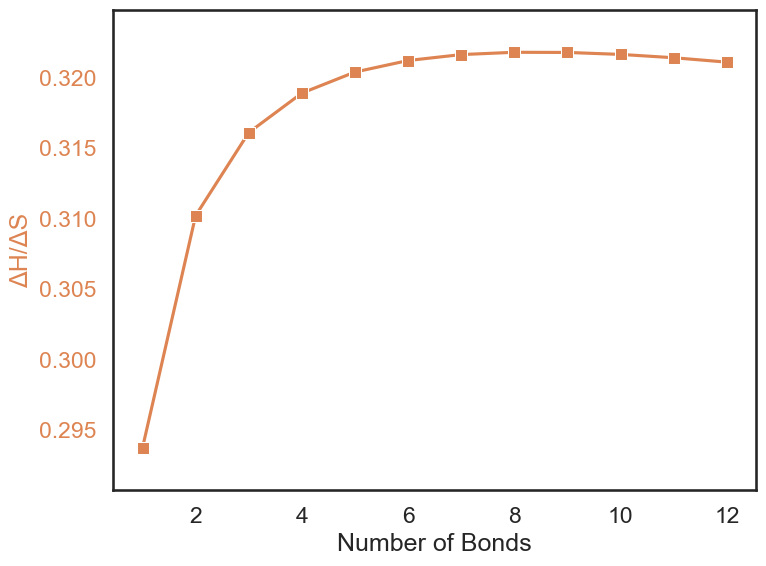

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

sps = np.linspace(1, 12, 12)

dh = []
ds = []

for sp in sps:
    bonds = make_interface(int(sp), duplex_len=7, spacing_nm=10)
    H, S = predict_Tm2(bonds)
    dh.append(H)
    ds.append(S)

fig, ax2 = plt.subplots(figsize=(8, 6))
#ax2 = ax1.twinx()

# ΔS on right axis
sns.lineplot(
    x=sps,
    y=np.array(dh)/np.array(ds),
    ax=ax2,
    marker="s",
    label="ΔS",
    color = 'C1'
)

ax2.set_xlabel("Number of Bonds")
#ax1.set_ylabel("ΔH (kcal/mol)")
#ax2.set_ylabel("ΔH/ΔS")
#if ax1.get_legend() is not None:
#    ax1.get_legend().remove()

if ax2.get_legend() is not None:
    ax2.get_legend().remove()
# combine legends
#lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()


#ax1.set_ylim(min(dh) - 10, max(dh) + 10)
ax2.set_ylim(min(np.array(dh)/np.array(ds))-.003, max(np.array(dh)/np.array(ds))+.003)

#ax1.set_ylabel("ΔH (kcal/mol)", color="C0")
ax2.set_ylabel("ΔH/ΔS", color="C1")
#ax1.tick_params(axis="y", colors="C0")
ax2.tick_params(axis="y", colors="C1")
plt.tight_layout()
#plt.show()
plt.savefig('TheoreticalNumBonds_EntropyOverEnthalpy.svg', dpi = 600)

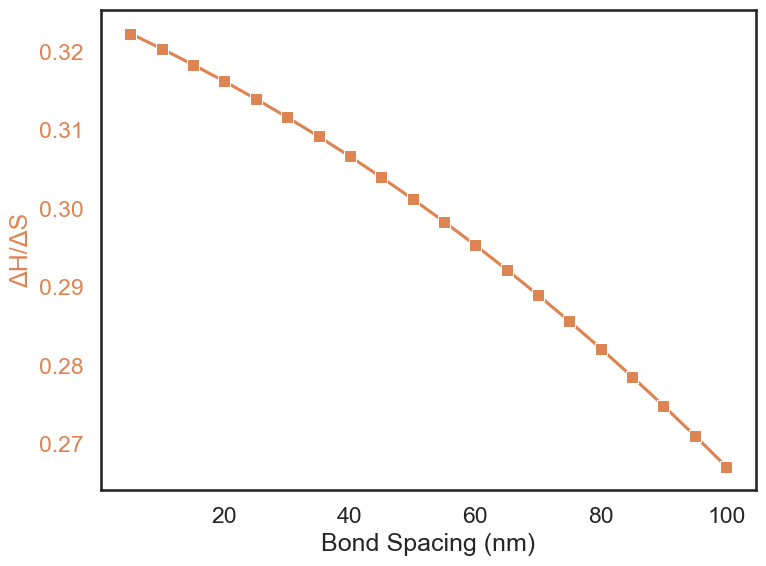

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sps = np.linspace(5, 100, 20)

dh = []
ds = []

for sp in sps:
    bonds = make_interface(5, duplex_len=7, spacing_nm=int(sp))
    H, S = predict_Tm2(bonds)
    dh.append(H)
    ds.append(S)

fig, ax2 = plt.subplots(figsize=(8, 6))
#ax2 = ax1.twinx()

# ΔS on right axis
sns.lineplot(
    x=sps,
    y=np.array(dh)/np.array(ds),
    ax=ax2,
    marker="s",
    label="ΔS",
    color = 'C1'
)

ax2.set_xlabel("Bond Spacing (nm)")
#ax1.set_ylabel("ΔH (kcal/mol)")
#ax2.set_ylabel("ΔH/ΔS")
#if ax1.get_legend() is not None:
#    ax1.get_legend().remove()

if ax2.get_legend() is not None:
    ax2.get_legend().remove()
# combine legends
#lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()


#ax1.set_ylim(min(dh) - 10, max(dh) + 10)
ax2.set_ylim(min(np.array(dh)/np.array(ds))-.003, max(np.array(dh)/np.array(ds))+.003)

#ax1.set_ylabel("ΔH (kcal/mol)", color="C0")
ax2.set_ylabel("ΔH/ΔS", color="C1")
#ax1.tick_params(axis="y", colors="C0")
ax2.tick_params(axis="y", colors="C1")
plt.tight_layout()
#plt.show()
plt.savefig('TheoreticalSpacing_EntropyOverEnthalpy.svg', dpi = 600)

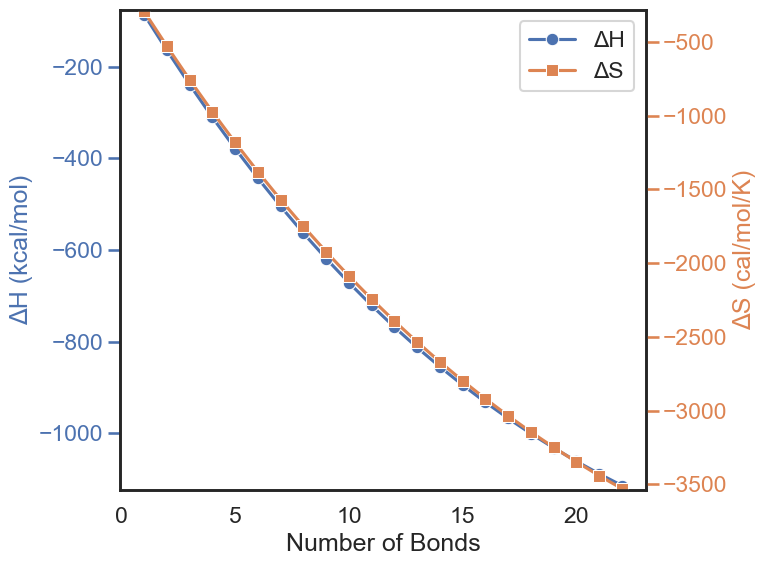

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sps = np.linspace(1, 22, 22)

dh = []
ds = []

for sp in sps:
    bonds = make_interface(int(sp), duplex_len=7, spacing_nm=10)
    H, S = predict_Tm2(bonds)
    dh.append(H)
    ds.append(S)

fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()

# ΔH on left axis
sns.lineplot(
    x=sps,
    y=dh,
    ax=ax1,
    marker="o",
    label="ΔH"
)

# ΔS on right axis
sns.lineplot(
    x=sps,
    y=ds,
    ax=ax2,
    marker="s",
    label="ΔS",
    color = 'C1'
)

ax1.set_xlabel("Number of Bonds")
ax1.set_ylabel("ΔH (kcal/mol)")
ax2.set_ylabel("ΔS (cal/mol/K)")
if ax1.get_legend() is not None:
    ax1.get_legend().remove()

if ax2.get_legend() is not None:
    ax2.get_legend().remove()
# combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="best"
)

ax1.set_ylim(min(dh) - 10, max(dh) + 10)
ax2.set_ylim(min(ds) - 10, max(ds) + 10)

ax1.set_ylabel("ΔH (kcal/mol)", color="C0")
ax2.set_ylabel("ΔS (cal/mol/K)", color="C1")
ax1.tick_params(axis="y", colors="C0")
ax2.tick_params(axis="y", colors="C1")
plt.tight_layout()
#plt.show()
pd.DataFrame({'Num_Bonds': np.asarray(sps, int), 'Enthalpy_kcal_mol': dh, 'Entropy_cal_mol_K': ds}).to_csv('TheoreticalNumBonds_Entropy_Enthalpy.csv', index=False)
plt.savefig('TheoreticalNumBonds_Entropy_Enthalpy.svg', dpi = 600)

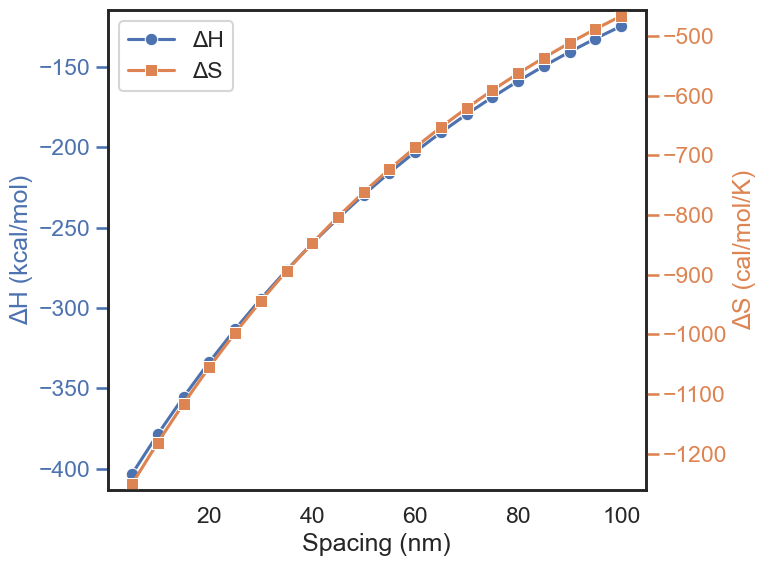

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sps = np.linspace(5, 100, 20)

dh = []
ds = []

for sp in sps:
    bonds = make_interface(5, duplex_len=7, spacing_nm=int(sp))
    H, S = predict_Tm2(bonds)
    dh.append(H)
    ds.append(S)

fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()

# ΔH on left axis
sns.lineplot(
    x=sps,
    y=dh,
    ax=ax1,
    marker="o",
    label="ΔH"
)

# ΔS on right axis
sns.lineplot(
    x=sps,
    y=ds,
    ax=ax2,
    marker="s",
    label="ΔS",
    color = 'C1'
)

ax1.set_xlabel("Spacing (nm)")
ax1.set_ylabel("ΔH (kcal/mol)")
ax2.set_ylabel("ΔS (cal/mol/K)")
if ax1.get_legend() is not None:
    ax1.get_legend().remove()

if ax2.get_legend() is not None:
    ax2.get_legend().remove()
# combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="best"
)

ax1.set_ylim(min(dh) - 10, max(dh) + 10)
ax2.set_ylim(min(ds) - 10, max(ds) + 10)

ax1.set_ylabel("ΔH (kcal/mol)", color="C0")
ax2.set_ylabel("ΔS (cal/mol/K)", color="C1")
ax1.tick_params(axis="y", colors="C0")
ax2.tick_params(axis="y", colors="C1")
plt.tight_layout()
#plt.show()
pd.DataFrame({'Spacing_nm': sps, 'Enthalpy_kcal_mol': dh, 'Entropy_cal_mol_K': ds}).to_csv('TheoreticalSpacing_Entropy_Enthalpy.csv', index=False)
plt.savefig('TheoreticalSpacing_Entropy_Enthalpy.svg', dpi = 600)

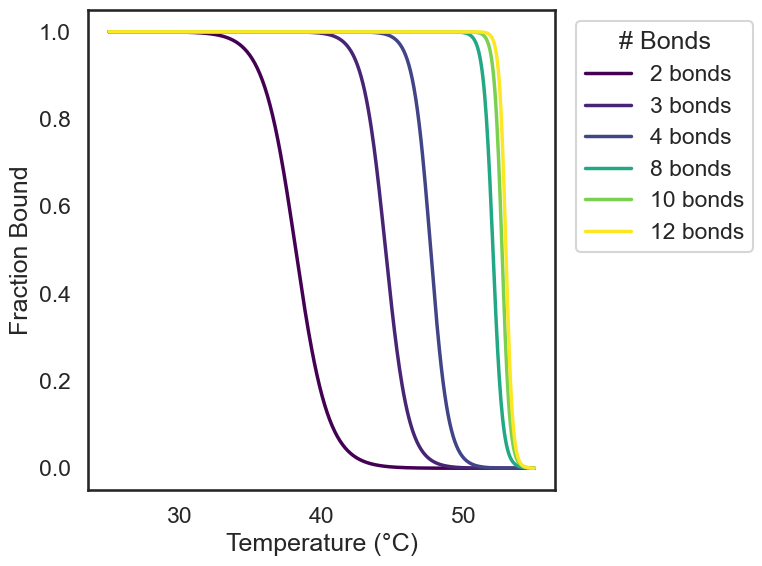

In [33]:
sns.set_theme(style="white", context="talk")

sps = [ 2, 3, 4, 8, 10,12]

# perceptually uniform colormap
cmap = plt.cm.viridis
norm = plt.Normalize(min(sps), max(sps))

fig, ax = plt.subplots(figsize=(8, 6))

for sp in sps:
    bonds = make_interface(sp, duplex_len=7, spacing_nm=4)
    T, f = predict_Tm1(bonds)

    sns.lineplot(
        x=T,
        y=f,
        ax=ax,
        color=cmap(norm(sp)),
        linewidth=2.5,
        label=f"{sp} bonds"
    )

ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Fraction Bound")
ax.set_ylim(-0.05, 1.05)
ax.legend(title="# Bonds", bbox_to_anchor=(1.02, 1), loc="upper left")

# colorbar showing bond count
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
#cbar = plt.colorbar(sm, ax=ax)
#cbar.set_label("Number of Bonds")

plt.tight_layout()
#plt.show()
plt.savefig('TheoreticalNumBonds_FracBound.svg', dpi = 600)

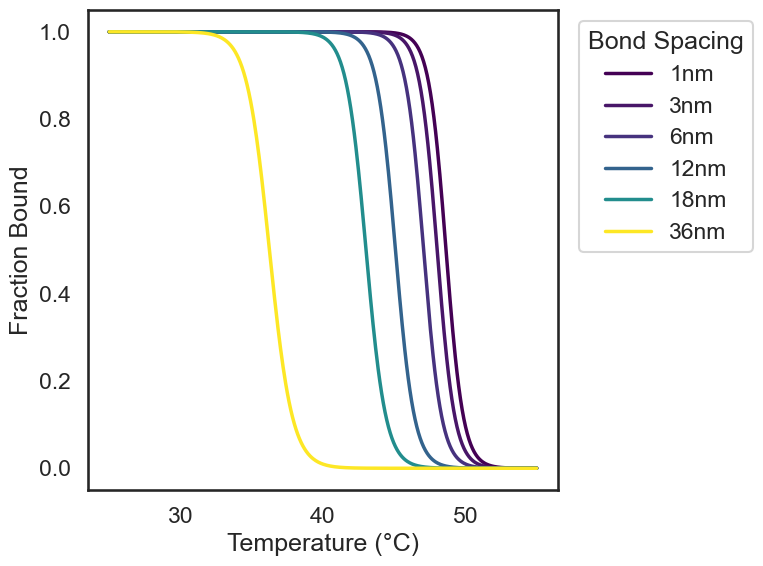

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", context="talk")

sps = [1, 3, 6, 12, 18, 36]

# perceptually uniform colormap
cmap = plt.cm.viridis
norm = plt.Normalize(min(sps), max(sps))

fig, ax = plt.subplots(figsize=(8, 6))

for sp in sps:
    bonds = make_interface(4, duplex_len=7, spacing_nm=sp)
    T, f = predict_Tm1(bonds)

    sns.lineplot(
        x=T,
        y=f,
        ax=ax,
        color=cmap(norm(sp)),
        linewidth=2.5,
        label=f"{sp}nm"
    )

ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Fraction Bound")
ax.set_ylim(-0.05, 1.05)
ax.legend(title="Bond Spacing", bbox_to_anchor=(1.02, 1), loc="upper left")

# colorbar showing bond count
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
#cbar = plt.colorbar(sm, ax=ax)
#cbar.set_label("Number of Bonds")

plt.tight_layout()
#plt.show()
plt.savefig('TheoreticalBondSpacing_FracBound.svg', dpi = 600)

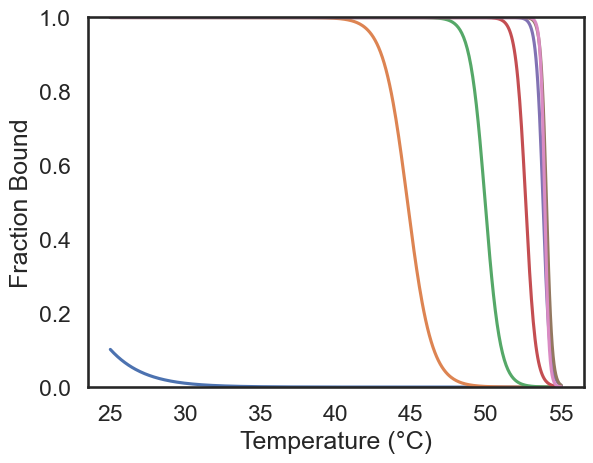

In [24]:
tm = []
for sp in [1,3,5,8,12,15,20]:
    bonds=make_interface(sp, duplex_len=7, spacing_nm=3)
    T, f = predict_Tm1(bonds)

    plt.plot(T, f)
    plt.xlabel("Temperature (°C)")
    plt.ylabel("Fraction Bound")
    plt.ylim(0, 1)

## Best model evaluated like the ML model (rank-rank, pred-vs-exp, Fig 6d metrics)

10-fold out-of-fold predictions (same `random_state=0` as the ML). Saves rank-rank and predicted-vs-experimental data+plots, plus a performance row in the **ML Fig 6d format** (`Model, Mean_Fold_Rho, Std_Fold_Rho, OOF_Rho`) and a combined table so the phenomenological model can be plotted on the same bar chart as the ML models.

> Note: the phenomenological model is scored on its 230-construct set (no 9/6); the ML Fig 6d used the 247-construct `df_Tm_median` — so this is a near, not exact, head-to-head.

Phenomenological (N-scaled):  OOF rho=0.884  mean-fold rho=0.866 +/- 0.082


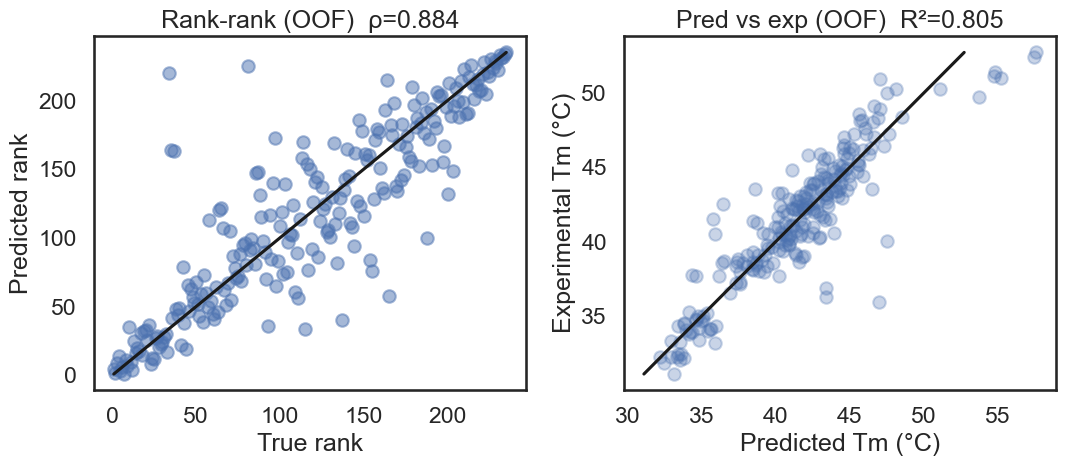

                      Model  Mean_Fold_Rho  Std_Fold_Rho  OOF_Rho
Phenomenological (N-scaled)          0.866         0.082    0.884
                    XGBoost          0.862         0.088    0.861
               RandomForest          0.816         0.130    0.814
          Linear Regression          0.548         0.181    0.576
       Quadratic Regression          0.548         0.148    0.558
           Sum of Sequences          0.173         0.227    0.188


In [25]:
# ===== Best model evaluated ML-style (rank-rank, pred-vs-exp, Fig-6d metrics) =====
from scipy.stats import rankdata
import os
OUT = "Figure4_PhenomenologicalModel/Phenomenological_Model"; os.makedirs(OUT, exist_ok=True)
codes = agg['code'].values

# 10-fold out-of-fold predictions (random_state=0, same folds as the ML model)
kf = KFold(10, shuffle=True, random_state=0)
oof = np.full(n, np.nan); fold_rhos = []
for tr, te in kf.split(np.arange(n)):
    p = fit('Nscale', idx=tr)
    pr = np.array([predict(Bl[j], p, 'Nscale') for j in te]); oof[te] = pr
    fold_rhos.append(spearmanr(Y[te], pr).correlation)
oof_rho = spearmanr(Y, oof).correlation
mean_fold, std_fold = float(np.mean(fold_rhos)), float(np.std(fold_rhos))
print("Phenomenological (N-scaled):  OOF rho=%.3f  mean-fold rho=%.3f +/- %.3f" % (oof_rho, mean_fold, std_fold))

# (6b) rank-rank
rt = rankdata(Y, method='average'); rp = rankdata(oof, method='average')
pd.DataFrame({'code': codes, 'true_Tm': Y, 'pred_Tm_oof': oof, 'true_rank': rt, 'pred_rank': rp}).to_csv(f"{OUT}/rank_rank.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].scatter(rt, rp, alpha=0.5); lo, hi = min(rt.min(), rp.min()), max(rt.max(), rp.max())
ax[0].plot([lo, hi], [lo, hi], 'k-'); ax[0].set(xlabel="True rank", ylabel="Predicted rank", title=f"Rank-rank (OOF)  ρ={oof_rho:.3f}")
# (6c) predicted vs experimental
pd.DataFrame({'code': codes, 'pred_Tm_oof': oof, 'exp_Tm': Y}).to_csv(f"{OUT}/pred_vs_exp.csv", index=False)
r2 = 1 - np.sum((oof - Y)**2)/np.sum((Y - Y.mean())**2)
ax[1].scatter(oof, Y, alpha=0.3); ax[1].plot([Y.min(), Y.max()], [Y.min(), Y.max()], 'k-')
ax[1].set(xlabel="Predicted Tm (°C)", ylabel="Experimental Tm (°C)", title=f"Pred vs exp (OOF)  R²={r2:.3f}")
plt.tight_layout(); fig.savefig(f"{OUT}/rank_rank.svg", bbox_inches="tight"); plt.close(fig)
# Fig 4b: dedicated single-panel OUT-OF-FOLD predicted-vs-experimental Tm (not the fit-to-all in-sample)
rmsd_oof = float(np.sqrt(np.mean((oof - Y)**2)))
f4b, a4b = plt.subplots(figsize=(5.2, 5.0))
a4b.scatter(oof, Y, alpha=0.4, color="#4C78A8", edgecolor="white", linewidth=0.4)
_lo = min(oof.min(), Y.min()) - 1; _hi = max(oof.max(), Y.max()) + 1
a4b.plot([_lo, _hi], [_lo, _hi], "r--", lw=1.5, label="y = x")
a4b.set(xlabel="Predicted T$_m$ (\u00b0C, out-of-fold)", ylabel="Experimental T$_m$ (\u00b0C)",
        title=f"Phenomenological model, 10-fold out-of-fold\n\u03c1={oof_rho:.3f}, RMSD={rmsd_oof:.2f} \u00b0C, R\u00b2={r2:.3f}")
a4b.legend(loc="upper left", fontsize=9); f4b.tight_layout()
f4b.savefig(f"{OUT}/pred_vs_exp.svg", bbox_inches="tight"); plt.close(f4b)
# per-interface best-model predictions -> OUT-OF-FOLD (the Fig 4b source; was in-sample)
pd.DataFrame({"code": codes, "Tm_C": Y, "Tm_pred": oof}).to_csv("interfaces_newTm_bestmodel.csv", index=False)
plt.show()

# (6d-format) performance row + combine with the ML model comparison for a joint bar plot
perf = pd.DataFrame([{'Model': 'Phenomenological (N-scaled)', 'Mean_Fold_Rho': mean_fold, 'Std_Fold_Rho': std_fold, 'OOF_Rho': oof_rho}])
perf.to_csv(f"{OUT}/performance.csv", index=False)
mlf = "Figure6_MachineLearning/Fig6d_ModelComparison_SpearmanRho/data.csv"
if os.path.exists(mlf):
    ml = pd.read_csv(mlf)[['Model', 'Mean_Fold_Rho', 'Std_Fold_Rho', 'OOF_Rho']]
    comb = pd.concat([ml, perf], ignore_index=True).sort_values('OOF_Rho', ascending=False)
    comb.to_csv(f"{OUT}/combined_model_performance.csv", index=False)
    print(comb.round(3).to_string(index=False))


## Fair head-to-head: ML models rerun on the SAME 230-construct set

Same 10-fold CV (`random_state=0`). Features = 11-element per-helix SantaLucia ΔG (make_Energy_Array convention). Saved **separately** to `ml_rerun_230set.csv`; the combined fair table (ML + phenomenological) is `combined_fair_230set.csv`.

In [26]:
# ===== ML models rerun on the SAME construct set as the phenomenological model (fair head-to-head) =====
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
try:
    from xgboost import XGBRegressor; HAVE_XGB = True
except Exception:
    HAVE_XGB = False

# 11-element per-helix dG feature (SantaLucia, odd physical helix = make_Energy_Array convention)
def _featdG(code):
    x = np.zeros(11)
    for i, ch in enumerate(code):
        c = '5' if ch == 'X' else ch
        if c == '0': continue
        th = TH.get(c, {}).get(2*i+1)
        if th is None: return None
        x[i] = th[0] - 310.15*th[1]/1000.0            # dG at 37 C
    return x
Xml = np.vstack([_featdG(c) for c in agg['code']])

class SumModel:                                        # additive baseline: Tm from total dG
    def fit(self, X, y): self.m = LinearRegression().fit(X.sum(1, keepdims=True), y); return self
    def predict(self, X): return self.m.predict(X.sum(1, keepdims=True))
models = {'Linear Regression': LinearRegression(),
          'Quadratic Regression': make_pipeline(PolynomialFeatures(2, include_bias=False, interaction_only=True), LinearRegression()),
          'RandomForest': RandomForestRegressor(n_estimators=300, random_state=0),
          'Sum of Sequences': SumModel()}
if HAVE_XGB:
    models['XGBoost'] = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8,
                                     colsample_bytree=0.8, tree_method='hist', random_state=0)

def _cvml(model):
    kf = KFold(10, shuffle=True, random_state=0); oof = np.empty(n); fr = []
    for tr, te in kf.split(Xml):
        model.fit(Xml[tr], Y[tr]); p = model.predict(Xml[te]); oof[te] = p; fr.append(spearmanr(Y[te], p).correlation)
    return float(np.mean(fr)), float(np.std(fr)), spearmanr(Y, oof).correlation
rows = []
for name, m in models.items():
    mf, sf, oof = _cvml(m); rows.append({'Model': name, 'Mean_Fold_Rho': mf, 'Std_Fold_Rho': sf, 'OOF_Rho': oof})
ml230 = pd.DataFrame(rows).sort_values('OOF_Rho', ascending=False)
ml230.to_csv(f"Figure4_PhenomenologicalModel/Phenomenological_Model/ml_rerun_{n}set.csv", index=False)       # separate from previous ML results
# combined fair table (ML + phenomenological on the SAME 230 set)
ph = pd.read_csv("Figure4_PhenomenologicalModel/Phenomenological_Model/performance.csv")
comb = pd.concat([ml230, ph], ignore_index=True).sort_values('OOF_Rho', ascending=False)
comb.to_csv(f"Figure4_PhenomenologicalModel/Phenomenological_Model/combined_fair_{n}set.csv", index=False)
print(comb[['Model', 'Mean_Fold_Rho', 'Std_Fold_Rho', 'OOF_Rho']].round(3).to_string(index=False))


                      Model  Mean_Fold_Rho  Std_Fold_Rho  OOF_Rho
Phenomenological (N-scaled)          0.866         0.082    0.884
                    XGBoost          0.848         0.103    0.872
               RandomForest          0.762         0.132    0.800
       Quadratic Regression          0.682         0.140    0.685
          Linear Regression          0.606         0.146    0.645
           Sum of Sequences          0.060         0.313    0.055
